## Objective

Todo

## Setup and data loading

### Imports and settings

In [31]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

RANDOM_STATE = 201

### File paths

In [32]:
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ACME-HappinessSurvey2020.csv"

### Load and preview the data

In [33]:
raw_df = pd.read_csv(RAW_DATA_PATH)

print(f"Rows: {raw_df.shape[0]}")
print(f"Columns: {raw_df.shape[1]}")

raw_df.head()

Rows: 126
Columns: 7


,Y,X1,X2,X3,X4,X5,X6
0,0,3,3,3,4,2,4
1,0,3,2,3,5,4,3
2,1,5,3,3,3,3,5
3,0,5,4,3,3,3,5
4,0,5,4,3,3,3,5


## Data quality checks

### Expected columns and data types

In [34]:
TARGET_COLUMN = "Y"
FEATURE_COLUMNS = ["X1", "X2", "X3", "X4", "X5", "X6"]

expected_columns = [TARGET_COLUMN, *FEATURE_COLUMNS]

assert not raw_df.empty, "The dataset is empty."
assert raw_df.columns.is_unique, "Column names are not unique."
assert set(raw_df.columns) == set(expected_columns), "Unexpected or missing columns."

raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 126 entries, 0 to 125
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Y       126 non-null    int64
 1   X1      126 non-null    int64
 2   X2      126 non-null    int64
 3   X3      126 non-null    int64
 4   X4      126 non-null    int64
 5   X5      126 non-null    int64
 6   X6      126 non-null    int64
dtypes: int64(7)
memory usage: 7.0 KB


### Missing values and unique value counts

In [35]:
quality_summary = pd.DataFrame(
    {
        "dtype": raw_df.dtypes,
        "missing_count": raw_df.isna().sum(),
        "missing_pct": raw_df.isna().mean().mul(100).round(1),
        "unique_count": raw_df.nunique(),
    }
)

quality_summary

,dtype,missing_count,missing_pct,unique_count
Y,int64,0,0.0,2
X1,int64,0,0.0,4
X2,int64,0,0.0,5
X3,int64,0,0.0,5
X4,int64,0,0.0,5
X5,int64,0,0.0,5
X6,int64,0,0.0,5


### Values outside the allowed sets

In [36]:
allowed_values = {column: [1, 2, 3, 4, 5] for column in FEATURE_COLUMNS}
allowed_values[TARGET_COLUMN] = [0, 1]

invalid_counts = {}

for column in expected_columns:
    values = raw_df[column]
    invalid_counts[column] = (
        values.notna() & ~values.isin(allowed_values[column])
    ).sum()

pd.Series(invalid_counts, name="invalid_count")

Y     0
X1    0
X2    0
X3    0
X4    0
X5    0
X6    0
Name: invalid_count, dtype: int64

### Repeated rows and answer patterns

An **answer pattern** is one complete combination of scores across X1–X6.
A pattern repeats when at least two rows share those six scores.

The table includes every repeated answer pattern:

- **row_count:** Number of original rows with that pattern.
- **target_count:** Number of distinct happiness labels within that pattern.
  A value of 1 means all labels agree. A value of 2 means both labels occur.

In [37]:
profile_summary = (
    raw_df.groupby(FEATURE_COLUMNS, dropna=False)
    .agg(
        row_count=(TARGET_COLUMN, "size"),
        target_count=(TARGET_COLUMN, "nunique"),
    )
    .reset_index()
)

repeated_answer_patterns = (
    profile_summary.loc[profile_summary["row_count"].gt(1)]
    .sort_values("target_count", ascending=False, kind="stable")
    .reset_index(drop=True)
)

print(f"Exact duplicate rows beyond the first occurrence: {raw_df.duplicated().sum()}")
print(f"Answer patterns that occur at least twice: {len(repeated_answer_patterns)}")
print(
    "Repeated answer patterns with both target labels: "
    f"{repeated_answer_patterns['target_count'].gt(1).sum()}"
)

print("\nRepeated Answer Patterns")

display(repeated_answer_patterns)

Exact duplicate rows beyond the first occurrence: 16
Answer patterns that occur at least twice: 19
Repeated answer patterns with both target labels: 7

Repeated Answer Patterns


,X1,X2,X3,X4,X5,X6,row_count,target_count
0,4,2,3,3,4,4,2,2
1,4,2,4,4,4,4,3,2
2,4,3,3,4,2,4,2,2
3,5,2,3,3,2,5,2,2
4,5,2,4,4,5,5,3,2
5,5,3,3,3,5,3,2,2
6,5,3,3,4,4,5,3,2
7,3,2,4,4,4,5,2,1
8,3,3,1,3,3,4,2,1
9,4,1,3,4,4,4,2,1


## Data split and EDA

### Reserve the test set

In [38]:
from sklearn.model_selection import train_test_split

X = raw_df[FEATURE_COLUMNS].copy()
y = raw_df[TARGET_COLUMN].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

train_df = X_train.join(y_train)

print(f"Training rows: {len(X_train)}")
print(f"Test rows reserved: {len(X_test)}")

Training rows: 100
Test rows reserved: 26


### Check the training class balance

In [39]:
target_summary = (
    y_train.value_counts()
    .reindex([0, 1])
    .to_frame("count")
)

target_summary["percentage"] = (
    target_summary["count"].div(len(y_train)).mul(100).round(1)
)

target_summary

,count,percentage
Y,,
0,45,45.0
1,55,55.0


### Explore survey scores by happiness label

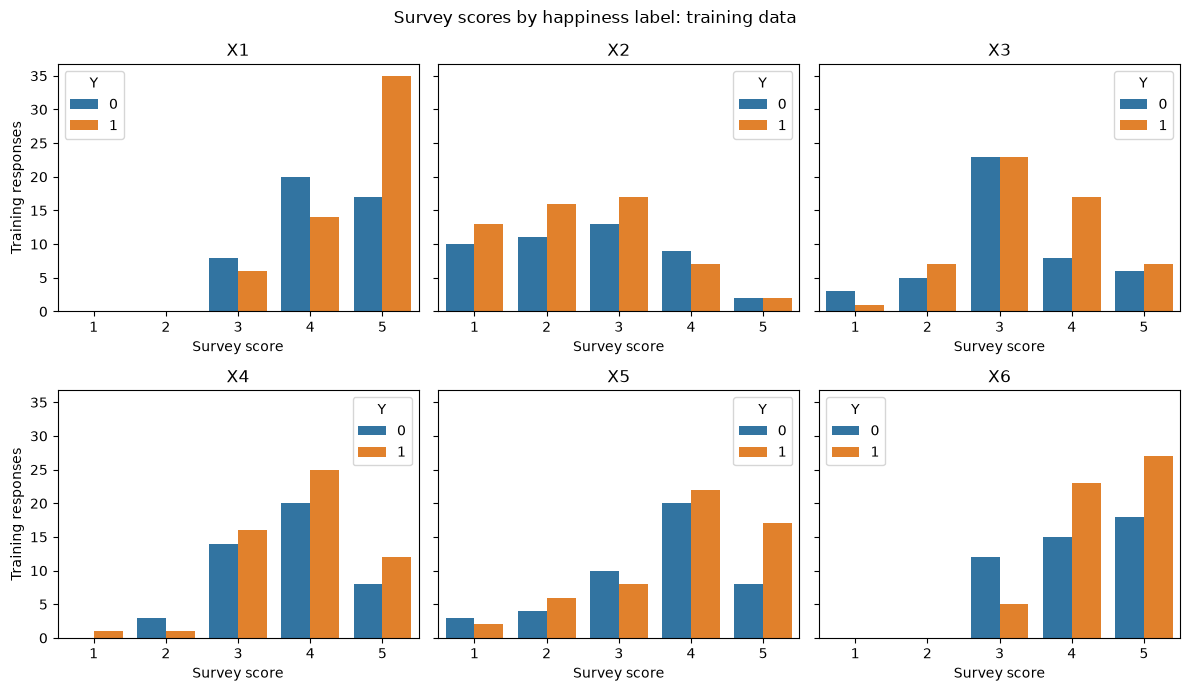

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharey=True)

for column, ax in zip(FEATURE_COLUMNS, axes.flat):
    sns.countplot(
        data=train_df,
        x=column,
        hue=TARGET_COLUMN,
        order=[1, 2, 3, 4, 5],
        hue_order=[0, 1],
        ax=ax,
    )
    ax.set_title(column)
    ax.set_xlabel("Survey score")
    ax.set_ylabel("Training responses")

fig.suptitle("Survey scores by happiness label: training data")
fig.tight_layout()
plt.show()

### Examine correlations

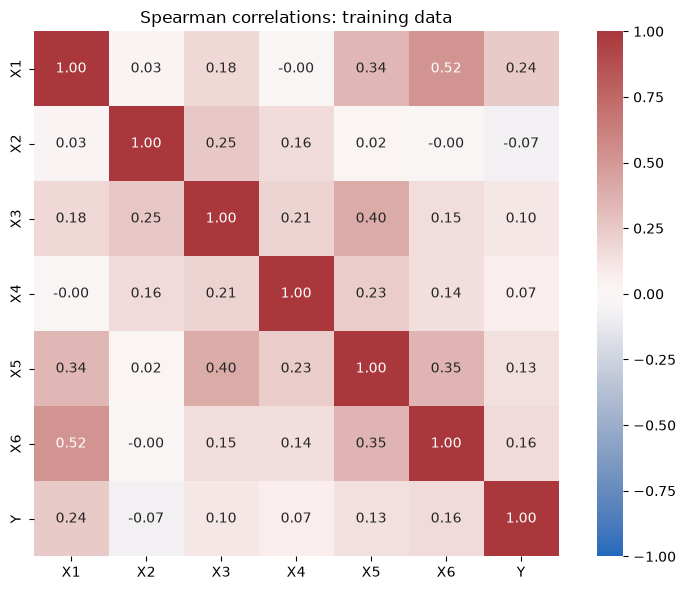

In [41]:
spearman_corr = train_df[
    [*FEATURE_COLUMNS, TARGET_COLUMN]
].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    cmap="vlag",
    square=True,
    ax=ax,
)

ax.set_title("Spearman correlations: training data")
fig.tight_layout()
plt.show()

## Baseline and model comparison

## Baseline and model comparison

Compare a majority baseline, logistic regression, a decision tree,
and a random forest using all six survey questions.

Select hyperparameters by accuracy. Report balanced accuracy as a
secondary metric. Accuracy gives each incorrect prediction equal cost.

Use five-fold stratified cross-validation repeated ten times to
compare models. Use the same outer splits for every model.

Within each outer fitting set, use five-fold stratified cross-validation
to select hyperparameters. Evaluate the selected model on the outer
validation set.

Search these parameters:

- Logistic regression: regularization strength (`C`).
- Decision tree: maximum depth and minimum samples per leaf.
- Random forest: features considered per split and minimum samples per leaf.

Keep other model parameters at their defaults. Set random seeds for
reproducible splits and tree fitting.

Keep the reserved test set for final evaluation.

### Imports

In [42]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_validate,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

### Validation splits, scoring, models, and parameter searches

In [43]:
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=RANDOM_STATE,
)

cv_splits = list(cv.split(X_train, y_train))

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
}

models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(),
    ),
    "Decision tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
    ),
    "Random forest": RandomForestClassifier(
        random_state=RANDOM_STATE,
    ),
}

param_grids = {
    "Logistic regression": {
        # Compare stronger and weaker regularization around the default, 1.
        "logisticregression__C": [0.01, 0.1, 1, 10, 100],
    },
    "Decision tree": {
        # Compare shallow trees with unrestricted depth.
        "max_depth": [1, 2, 3, None],
        # Compare the default with larger groups supporting each prediction.
        "min_samples_leaf": [1, 5, 10],
    },
    "Random forest": {
        # Compare default feature sampling with considering all six features.
        "max_features": ["sqrt", None],
        # Control tree complexity through the minimum leaf size.
        "min_samples_leaf": [1, 5, 10],
    },
}

for name, param_grid in param_grids.items():
    models[name] = GridSearchCV(
        models[name],
        param_grid=param_grid,
        scoring="accuracy",
        cv=inner_cv,
        error_score="raise",
    )

### Train, tune, and compare

In [44]:
cv_results = {}
comparison_rows = []

for name, model in models.items():
    print(f"Evaluating {name}...", flush=True)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv_splits,
        scoring=scoring,
        return_train_score=True,
        return_estimator=True,
        error_score="raise",
    )

    cv_results[name] = scores

    comparison_rows.append(
        {
            "model": name,
            "train_accuracy": scores["train_accuracy"].mean(),
            "cv_accuracy": scores["test_accuracy"].mean(),
            "cv_accuracy_sd": scores["test_accuracy"].std(ddof=1),
            "cv_balanced_accuracy": scores["test_balanced_accuracy"].mean(),
        }
    )

comparison = pd.DataFrame(comparison_rows).set_index("model")

baseline_accuracy = comparison.loc["Majority baseline", "cv_accuracy"]

comparison["gain_vs_baseline_pp"] = (
    comparison["cv_accuracy"] - baseline_accuracy
).mul(100)

comparison = comparison.sort_values("cv_accuracy", ascending=False)

display(comparison.round(3))

Evaluating Majority baseline...
Evaluating Logistic regression...
Evaluating Decision tree...
Evaluating Random forest...


,train_accuracy,cv_accuracy,cv_accuracy_sd,cv_balanced_accuracy,gain_vs_baseline_pp
model,,,,,
Decision tree,0.710,0.589,0.080,0.578,3.9
Majority baseline,0.550,0.550,0.000,0.500,0.0
Random forest,0.822,0.548,0.102,0.538,-0.2
Logistic regression,0.592,0.539,0.067,0.505,-1.1


### Inspect the selected parameters

In [45]:
for name in param_grids:
    selected_parameters = pd.Series(
        [
            str(search.best_params_)
            for search in cv_results[name]["estimator"]
        ],
        name="parameters",
    )

    parameter_counts = (
        selected_parameters.value_counts()
        .rename("outer_folds")
        .to_frame()
    )

    print(name)
    display(parameter_counts)

Logistic regression


,outer_folds
parameters,
{'logisticregression__C': 0.01},34
{'logisticregression__C': 0.1},8
{'logisticregression__C': 1},6
{'logisticregression__C': 10},2


Decision tree


,outer_folds
parameters,
"{'max_depth': 1, 'min_samples_leaf': 1}",11
"{'max_depth': 3, 'min_samples_leaf': 5}",10
"{'max_depth': None, 'min_samples_leaf': 1}",5
"{'max_depth': 3, 'min_samples_leaf': 1}",5
"{'max_depth': None, 'min_samples_leaf': 5}",5
"{'max_depth': 2, 'min_samples_leaf': 10}",4
"{'max_depth': 1, 'min_samples_leaf': 10}",4
"{'max_depth': 2, 'min_samples_leaf': 5}",2
"{'max_depth': 1, 'min_samples_leaf': 5}",2


Random forest


,outer_folds
parameters,
"{'max_features': None, 'min_samples_leaf': 5}",14
"{'max_features': 'sqrt', 'min_samples_leaf': 1}",12
"{'max_features': None, 'min_samples_leaf': 10}",9
"{'max_features': None, 'min_samples_leaf': 1}",8
"{'max_features': 'sqrt', 'min_samples_leaf': 5}",5
"{'max_features': 'sqrt', 'min_samples_leaf': 10}",2


## Survey question selection

Compare each question's scores between happy and unhappy customers.

Use the Mann–Whitney U test with permutation p-values. This compares
ranked scores without assuming that the gaps between scores are equal.

Adjust p-values with the Bonferroni method because we test six questions.

The rank-biserial effect ranges from -1 to 1. Positive values mean
happy customers tend to give higher scores. Negative values mean
they tend to give lower scores.

These are exploratory comparisons using the training data. Each
comparison examines one question without adjusting for the others.
The calculations assume independent customer responses.

A non-significant result does not prove that a question is useless.
Do not remove questions based only on these tests.

In [46]:
from scipy.stats import PermutationMethod, mannwhitneyu

question_rows = []

for question in FEATURE_COLUMNS:
    happy_scores = X_train.loc[y_train == 1, question]
    unhappy_scores = X_train.loc[y_train == 0, question]

    result = mannwhitneyu(
        happy_scores,
        unhappy_scores,
        alternative="two-sided",
        method=PermutationMethod(
            n_resamples=9999,
            rng=RANDOM_STATE,
        ),
    )

    pair_count = len(happy_scores) * len(unhappy_scores)
    effect = 2 * result.statistic / pair_count - 1

    question_rows.append(
        {
            "question": question,
            "rank_biserial_effect": effect,
            "p_value": result.pvalue,
        }
    )

question_results = pd.DataFrame(question_rows).set_index("question")

question_results["adjusted_p_value"] = (
    question_results["p_value"] * len(FEATURE_COLUMNS)
).clip(upper=1)

question_results["significant_at_0.05"] = (
    question_results["adjusted_p_value"] < 0.05
)

display(question_results.sort_values("p_value").round(3))

,rank_biserial_effect,p_value,adjusted_p_value,significant_at_0.05
question,,,,
X1,0.255,0.020,0.120,False
X6,0.172,0.121,0.726,False
X5,0.147,0.187,1.000,False
X3,0.113,0.309,1.000,False
X2,-0.080,0.472,1.000,False
X4,0.074,0.499,1.000,False


## Final evaluation 
Keep all six survey questions for this evaluation.

Choose the model with the highest mean cross-validation accuracy.
Refit its existing search on all training responses. The search
selects parameters using cross-validation within the training data.

Evaluate the selected model and the majority baseline on the
reserved test set. Report accuracy, balanced accuracy, and an
approximate 95% Wilson confidence interval for test accuracy.

The interval describes uncertainty from the small test sample.
It does not include all uncertainty from model development or
possible differences between these customers and future customers.

A test accuracy of at least 73% meets the numerical target on this
sample. It does not establish that future accuracy is at least 73%.

Keep this as the final evaluation. Further changes based on these
test results would require a new independent evaluation.

In [47]:
from scipy.stats import binomtest
from sklearn.base import clone
from sklearn.metrics import balanced_accuracy_score

selected_name = comparison["cv_accuracy"].idxmax()

final_models = {
    selected_name: clone(models[selected_name]),
    "Majority baseline": clone(models["Majority baseline"]),
}

evaluation_rows = []

for name, model in final_models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    correct = int((predictions == y_test).sum())
    interval = binomtest(correct, len(y_test)).proportion_ci(
        confidence_level=0.95,
        method="wilson",
    )

    evaluation_rows.append(
        {
            "model": name,
            "cv_accuracy": comparison.loc[name, "cv_accuracy"],
            "test_correct": correct,
            "test_accuracy": correct / len(y_test),
            "test_balanced_accuracy": balanced_accuracy_score(
                y_test, predictions
            ),
            "ci_low": interval.low,
            "ci_high": interval.high,
        }
    )

final_results = pd.DataFrame(evaluation_rows).set_index("model")

print(f"Selected model: {selected_name}")
print(f"Training responses: {len(y_train)}")
print(f"Test responses: {len(y_test)}")
display(final_results.round(3))

test_accuracy = final_results.loc[selected_name, "test_accuracy"]
print(f"Meets the 73% test accuracy target: {test_accuracy >= 0.73}")

Selected model: Decision tree
Training responses: 100
Test responses: 26


,cv_accuracy,test_correct,test_accuracy,test_balanced_accuracy,ci_low,ci_high
model,,,,,,
Decision tree,0.589,15,0.577,0.56,0.389,0.745
Majority baseline,0.550,14,0.538,0.50,0.355,0.712


Meets the 73% test accuracy target: False


## Conclusions 